# Iris Flower Classification Using Machine Learning

## Internship: Oasis Infobyte (OIBSIP)
**Task 1 — Multi-Class Classification**

### Objective
Build and evaluate machine learning classification models
to predict Iris flower species using flower measurements.

### Models
- Logistic Regression
- Decision Tree Classifier

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix

In [11]:
# Import required libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris(as_frame=True)

# Create a DataFrame
df = iris.frame

# Display the first five rows
print("First 5 rows of the Iris Dataset:")
display(df.head())

# Display dataset dimensions
print("\nDataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

First 5 rows of the Iris Dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0



Dataset Shape: (150, 5)

Column Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target']

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


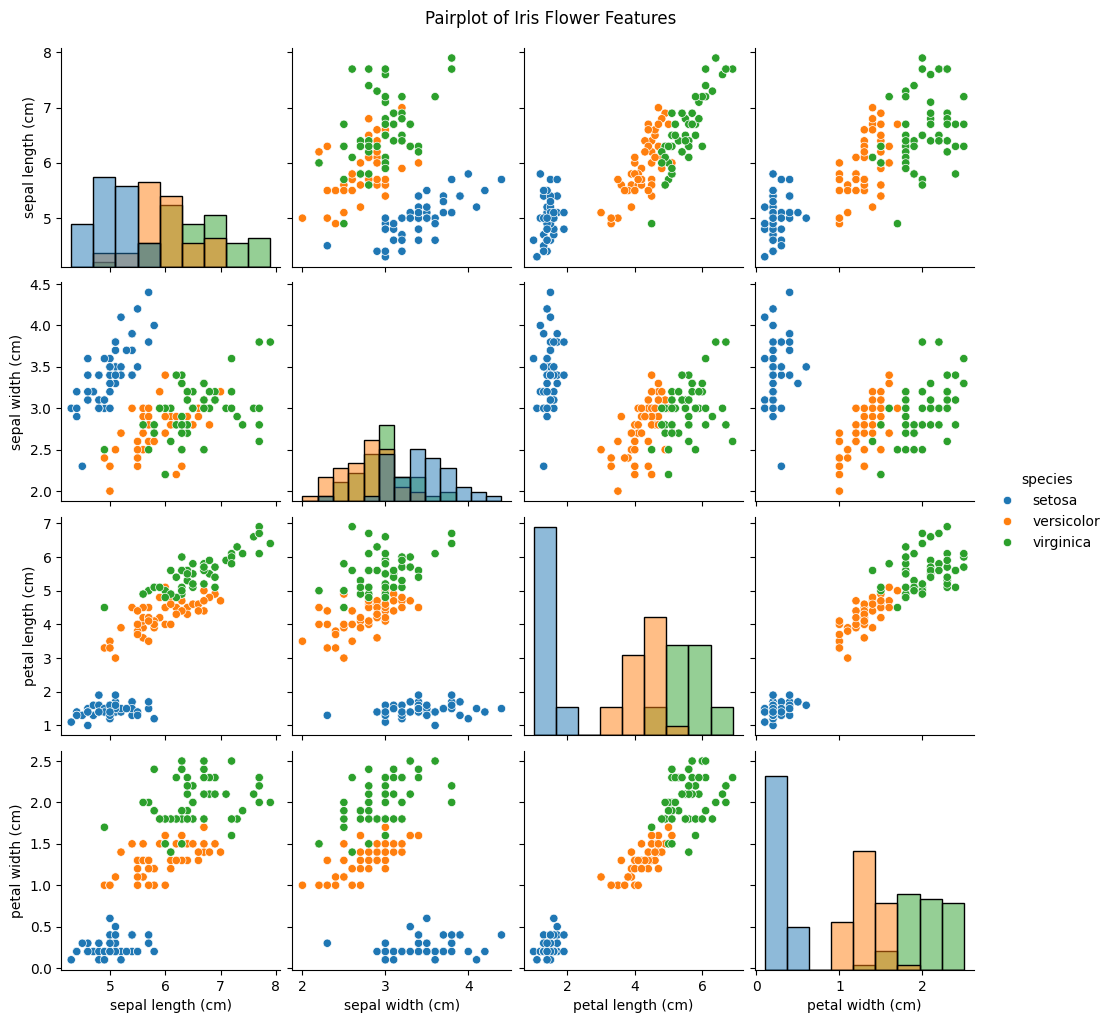

In [12]:
# Exploratory Data Analysis: Pairplot

# Rename the target column for clarity
df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

# Create pairplot
sns.pairplot(
    df,
    vars=iris.feature_names,
    hue="species",
    diag_kind="hist"
)

plt.suptitle("Pairplot of Iris Flower Features", y=1.02)
plt.show()

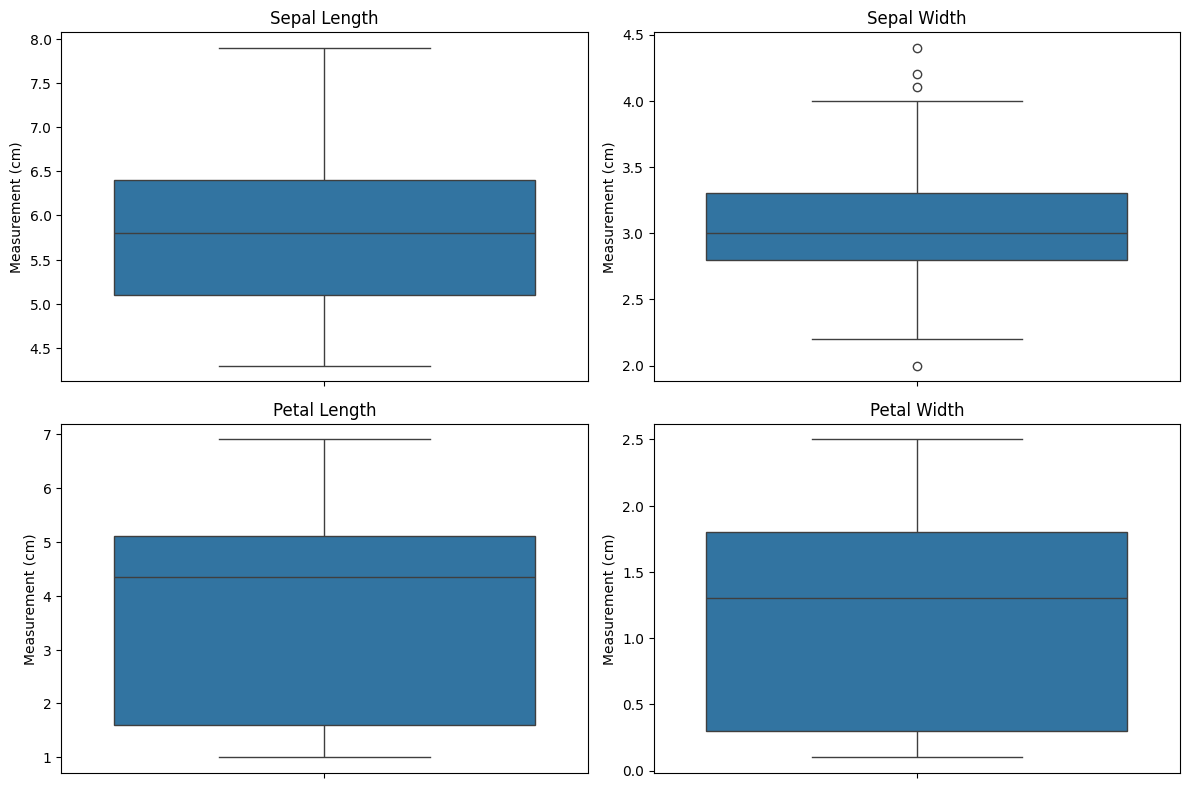

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

# Box plots to identify the distribution and outliers
# of each Iris flower measurement

features = iris.feature_names

plt.figure(figsize=(12, 8))

for i, feature in enumerate(features, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=iris.data[feature])
    plt.title(feature.replace(" (cm)", "").title())
    plt.ylabel("Measurement (cm)")

plt.tight_layout()
plt.show()



## Feature Selection

The Iris dataset contains four features:
- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

Petal length and petal width are generally more useful for distinguishing the three Iris species because their measurements show clearer separation between species. Sepal measurements can also provide useful information, but they may overlap more.

In this project, all four features are used to train the classification models.


In [14]:
# Step 7: Split the dataset and scale features

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate input features and target
X = iris.data
y = iris.target

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# Apply feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling completed successfully!")
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Training samples: 120
Testing samples: 30

Feature scaling completed successfully!
Scaled training data shape: (120, 4)
Scaled testing data shape: (30, 4)


Logistic Regression Results
----------------------------
Correct Predictions: 28 out of 30
Model Accuracy: 93.33 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



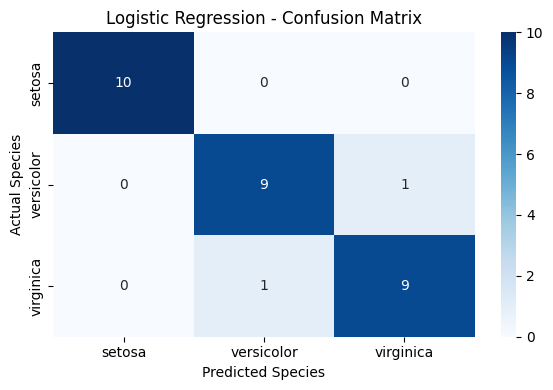

In [15]:
# Step 8: Train Logistic Regression Model

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create and train the model
lr_model = LogisticRegression(max_iter=200)
lr_model.fit(X_train_scaled, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test_scaled)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Results")
print("----------------------------")
print("Correct Predictions:",
      (y_test == lr_predictions).sum(), "out of", len(y_test))
print("Model Accuracy:", round(lr_accuracy * 100, 2), "%")


from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, lr_predictions,
                            target_names=iris.target_names))

# Confusion matrix
cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=iris.target_names,
            yticklabels=iris.target_names)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()


Decision Tree Model Results
----------------------------
Correct Predictions: 28 out of 30
Decision Tree Accuracy: 93.33 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



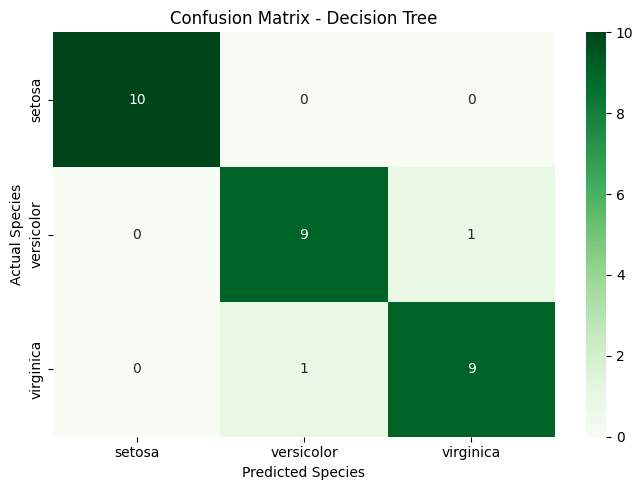

In [16]:

# Step 9: Train Decision Tree Model

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Create and train the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)

# Make predictions
dt_predictions = dt_model.predict(X_test_scaled)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, dt_predictions)

# Display results
print("Decision Tree Model Results")
print("----------------------------")
print("Correct Predictions:",
      (y_test == dt_predictions).sum(), "out of", len(y_test))
print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, dt_predictions))

# Plot confusion matrix
cm_dt = confusion_matrix(y_test, dt_predictions)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()


Model Accuracy Comparison
-------------------------
Logistic Regression: 93.33%
Decision Tree: 93.33%


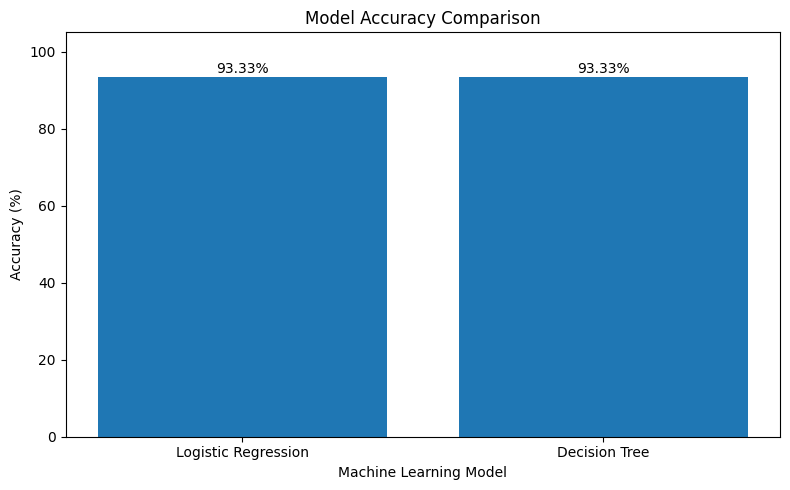

In [17]:

# Step 10: Model Accuracy Comparison

import matplotlib.pyplot as plt

# Compare model accuracies
models = ["Logistic Regression", "Decision Tree"]
accuracies = [lr_accuracy * 100, dt_accuracy * 100]

print("Model Accuracy Comparison")
print("-------------------------")

for model, accuracy in zip(models, accuracies):
    print(f"{model}: {accuracy:.2f}%")

# Plot comparison graph
plt.figure(figsize=(8, 5))

bars = plt.bar(models, accuracies)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)

# Display accuracy on each bar
for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300)
plt.show()


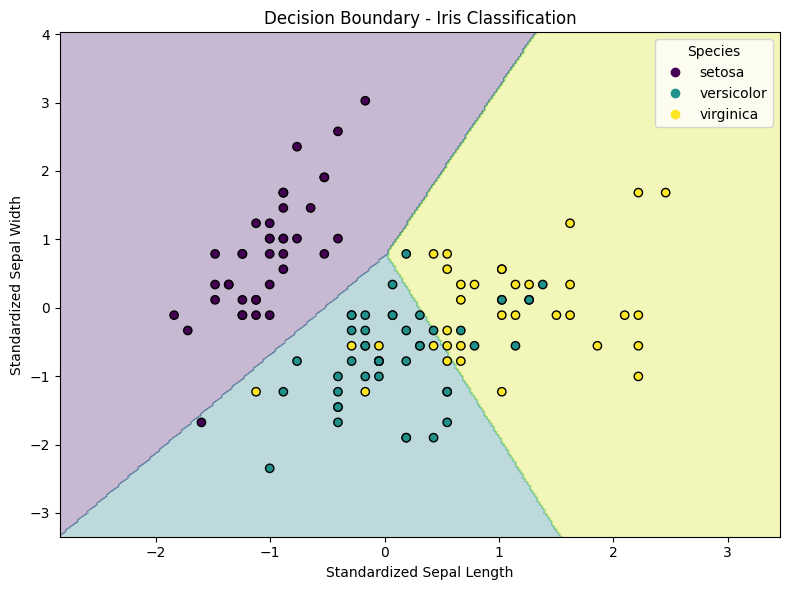

In [18]:

# Step 11: Decision Boundary Visualization

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

# Use the first two features for 2D visualization
X_train_2d = X_train_scaled[:, :2]
y_train_2d = y_train

# Train a separate model for visualization
visual_model = LogisticRegression(max_iter=200)
visual_model.fit(X_train_2d, y_train_2d)

# Create a grid
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Predict species for each grid point
Z = visual_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision regions
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")

# Plot training samples
scatter = plt.scatter(
    X_train_2d[:, 0],
    X_train_2d[:, 1],
    c=y_train_2d,
    cmap="viridis",
    edgecolors="black"
)

plt.title("Decision Boundary - Iris Classification")
plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Sepal Width")
plt.legend(
    handles=scatter.legend_elements()[0],
    labels=list(iris.target_names),
    title="Species"
)
plt.tight_layout()
plt.savefig("decision_boundary.png", dpi=300)
plt.show()



# Conclusion

## Project Summary
The Iris Flower Classification project uses supervised machine learning to classify iris flowers into three species: Setosa, Versicolor, and Virginica.

## Models Evaluated
- Logistic Regression
- Decision Tree Classifier

## Results
- Logistic Regression Accuracy: 93.33%
- Decision Tree Accuracy: 93.33%
- Both models achieved the same accuracy on the test dataset.

## Evaluation and Visualization
- Explored the Iris dataset using Pandas.
- Checked missing values and statistical summaries.
- Scaled features using StandardScaler.
- Evaluated models using accuracy, precision, recall, and F1-score.
- Visualized the confusion matrix and model accuracy comparison.
- Created a decision boundary visualization.

## Final Conclusion
Both models performed equally well on the current test split. Further evaluation using cross-validation can help assess their performance on different data splits.
